Author:  
Manuel Eugenio Morocho Cayamcela, PhD

Edited by: 

Nicole Carolina Benavides Leal

## Exploratory Data Analysis of the Titanic Dataset

The Titanic was a famous ocean liner that tragically sank on its maiden voyage in 1912. Considered at the time the largest and most luxurious ship in the world, it was a symbol of the opulence and technological progress of the era.

On April 10, 1912, the Titanic departed from Southampton, England, bound for New York. However, on the night of April 14–15, the ship struck an iceberg in the North Atlantic and sank within hours. The disaster killed more than 1,500 people, making it one of the deadliest maritime tragedies in history.

### Introduction

This activity introduces basic exploratory data analysis using pandas and data visualization. We will inspect the dataset's structure, review descriptive statistics, check for missing values, and use plots to assess the hypotheses below.

The dataset is hosted in this GitHub repository, so you do not need to download or share it separately.

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Each row represents one passenger, and each column records a passenger attribute.

The dataset contains these columns:

1. `PassengerId`: Unique passenger identifier.
2. `Survived`: Survival status (0 = no, 1 = yes).
3. `Pclass`: Ticket class (1 = first, 2 = second, 3 = third).
4. `Name`: Passenger's name.
5. `Sex`: Passenger's sex.
6. `Age`: Passenger's age.
7. `SibSp`: Number of siblings or spouses aboard.
8. `Parch`: Number of parents or children aboard.
9. `Ticket`: Ticket number.
10. `Fare`: Ticket fare.
11. `Cabin`: Cabin number.
12. `Embarked`: Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton).

### Dataset Inspection

In the code cell below, display the dataset dimensions, data types, missing-value counts, and descriptive statistics. Keep the outputs visible. Then use the Markdown cell to identify which columns have missing values and describe one observation from the statistics.

In [2]:
# Inspect the dataset: dimensions, data types, missing values, and descriptive statistics.

# 1. Dimensiones del conjunto de datos
print("DIMENSIONES DEL DATASET:")
print(df.shape)

# 2. Tipos de datos
print("\nTIPOS DE DATOS:")
print(df.dtypes)

# 3. Valores faltantes
print("\nVALORES FALTANTES:")
print(df.isnull().sum())

# 4. Estadísticas descriptivas
print("\nESTADÍSTICAS DESCRIPTIVAS:")
print(df.describe())

# 5. Información general
print("\nINFORMACIÓN GENERAL:")
df.info()

DIMENSIONES DEL DATASET:
(891, 12)

TIPOS DE DATOS:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

VALORES FALTANTES:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

ESTADÍSTICAS DESCRIPTIVAS:
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000 

**Inspection notes:** Summarize what you found in the inspection and whether any preprocessing is needed for the hypotheses below.

El análisis exploratorio de los datos permitió identificar 891 registros de pasajeros y 12 variables con respecto a las características personales, condiciones de viaje y supervivencia.

Se encontraron valores faltantes en las columnas de edad (177), camarote (687) y puerto de embarque (2).

Sin embargo, las variables principales para el desarrollo de las hipótesis, que son sexo (Sex), clase del pasajero (Pclass) y supervivencia (Survived), no presentan valores faltantes, por lo que no se necesita generar un proceso adicional. Dando paso a la resolución de las hipótesis.

### Hypothesis Testing

#### Hypothesis 1: Women were more likely to survive

Calculate the survival rate for each sex and create a clearly labeled chart to compare them.

Tasa de supervivencia por sexo (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


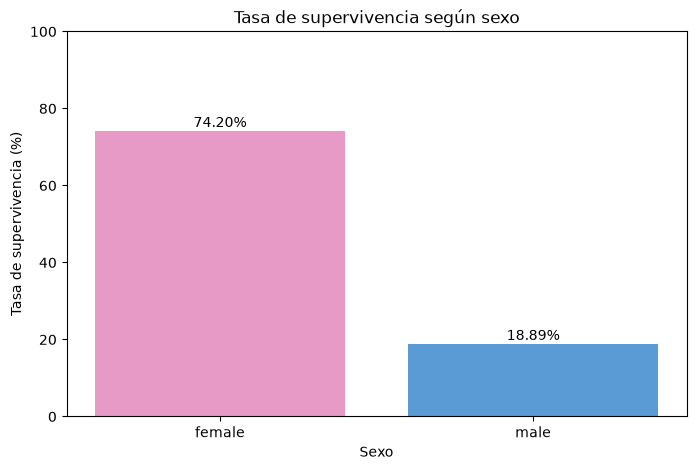

In [3]:
# Calculate survival rates by sex and visualize the comparison.

import matplotlib.pyplot as plt

# Calcular la tasa de supervivencia por sexo
survival_by_sex = df.groupby("Sex")["Survived"].mean() * 100

# Mostrar los resultados
print("Tasa de supervivencia por sexo (%):")
print(survival_by_sex.round(2))

# Crear el gráfico
plt.figure(figsize=(8, 5))

bars = plt.bar(
    survival_by_sex.index,
    survival_by_sex.values,
    color=["#E89AC7", "#5B9BD5"]
)

# Añadir títulos y etiquetas
plt.title("Tasa de supervivencia según sexo")
plt.xlabel("Sexo")
plt.ylabel("Tasa de supervivencia (%)")
plt.ylim(0, 100)

# Mostrar los porcentajes sobre las barras
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.show()

**Interpretation:** Which sex had the higher survival rate? Support your conclusion with the rates shown in your output.

Los resultados del análisis muestran que las mujeres tuvieron una tasa de supervivencia del 74,20 %, mientras que los hombres registraron una tasa del 18,89 %, es decir que aproximadamente 74 de cada 100 mujeres sobrevivieron al hundimiento del Titanic, en comparación con aproximadamente 19 de cada 100 hombres.
Esto permite evidenciar una asociación importante entre el sexo de los pasajeros y la supervivencia. Respaldando así la primera hipótesis, con base en datos y en cuestiones externas a ello, como es el caso de la prioridad que s ele da a niños y mujeres en situaciones de riesgo, en este contexto se estzba hundiendo el barco.

#### Hypothesis 2: First-class passengers were more likely to survive

Calculate the survival rate for each passenger class and create a clearly labeled chart to compare them.

Tasa de supervivencia por clase (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


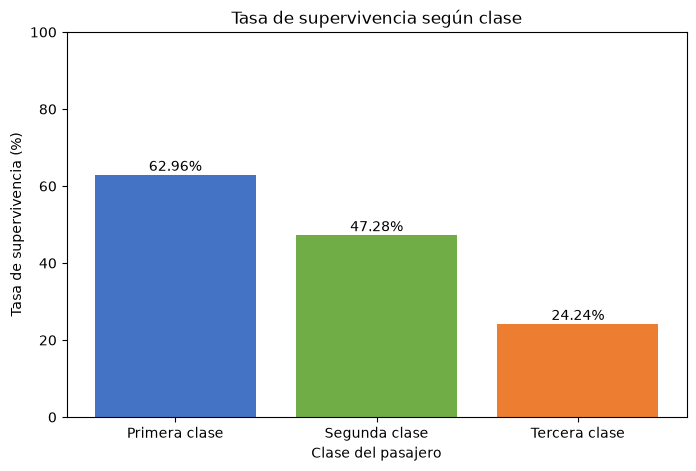

In [4]:
# Calculate survival rates by passenger class and visualize the comparison.

# Calcular la tasa de supervivencia por clase
survival_by_class = df.groupby("Pclass")["Survived"].mean() * 100

# Mostrar los resultados
print("Tasa de supervivencia por clase (%):")
print(survival_by_class.round(2))

# Crear el gráfico
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Primera clase", "Segunda clase", "Tercera clase"],
    survival_by_class.reindex([1, 2, 3]).values,
    color=["#4472C4", "#70AD47", "#ED7D31"]
)

# Añadir títulos
plt.title("Tasa de supervivencia según clase")
plt.xlabel("Clase del pasajero")
plt.ylabel("Tasa de supervivencia (%)")
plt.ylim(0, 100)

# Mostrar porcentajes
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.2f}%",
        ha="center"
    )

plt.show()

**Interpretation:** Which passenger class had the highest survival rate? Support your conclusion with the rates shown in your output.

Estos resultados evidencian que la proporción de pasajeros que sobrevivieron fue mayor en las clases superiores, como es el caso de primera clase (62,96%). Por lo tanto, los resultados respaldan la hipótesis. Sin embargo, los resultados representan una asociación estadística y no demuestran que la clase del pasajero haya sido la única causa de estas diferencias que se pueden analizar más a fondo.

**Conclusión:**
 
Mediante el uso de Python, Pandas y Matplotlib, se analizaron los datos del Titanic, permitiendo respaldar las dos hipótesis planteadas: las mujeres y los pasajeros de primera clase presentaron mayores tasas de supervivencia.

Sin embargo, ambas variables podrían analizarse conjuntamente, ya que una mujer que viajaba en primera clase reunía dos características asociadas con una mayor supervivencia.

En conclusión, de las 12 variables disponibles, el análisis se centró en el sexo, la clase del pasajero y la supervivencia, demostrando la utilidad del análisis exploratorio para identificar patrones y obtener información relevante, sin que esto implique necesariamente una relación causal.

### Assessment Rubric (10 points)

<table style="border-collapse: collapse; border-top: 1px solid; border-bottom: 1px solid;">
  <tr style="border-bottom: 1px solid;"><th style="border-left: none; border-right: none;" align="left">Criterion</th><th style="border-left: none; border-right: none;" align="right">Points</th></tr>
  <tr><td style="border-left: none; border-right: none;">Data inspection: required outputs and notes</td><td style="border-left: none; border-right: none;" align="right">2</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 1: survival rates by sex with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 2: survival rates by class with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;"><strong>Total</strong></td><td style="border-left: none; border-right: none;" align="right"><strong>10</strong></td></tr>
</table>